# ICC Style example gallery

This notebook shows how ICC Style is used for the analyses ICC members produce most often. The examples are grouped by analytical purpose, meaning what the chart has to help the reader do, rather than by plotting function. Every chart is plain Matplotlib or Seaborn; the package only supplies the theme, colors, formatters, titles and export.

> **All data in this notebook are synthetic.** They were generated with a fixed random seed to look plausible for consulting work, and are not real-world evidence. Company names such as "Competitor A" are placeholders.

**Running in Google Colab:** uncomment and run the next cell first to install the package.

In [1]:
# %pip install "icc-style[seaborn] @ git+https://github.com/insper-consulting-club/icc-style.git"

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

import icc_style as icc

icc.set_theme()

FIGURES = Path("figures")
SOURCE = (
    "Source: synthetic data created for the ICC Style gallery; not real-world evidence."
)
rng = np.random.default_rng(2025)

## 1. Comparing alternatives

### Ranking: where does the client stand?

A sorted horizontal bar chart works well for ranking a handful of alternatives. Only the client is colored; competitors stay gray, so the red carries the message. Values are labeled directly, which makes the x-axis redundant. Bars start at zero, as bar lengths must.

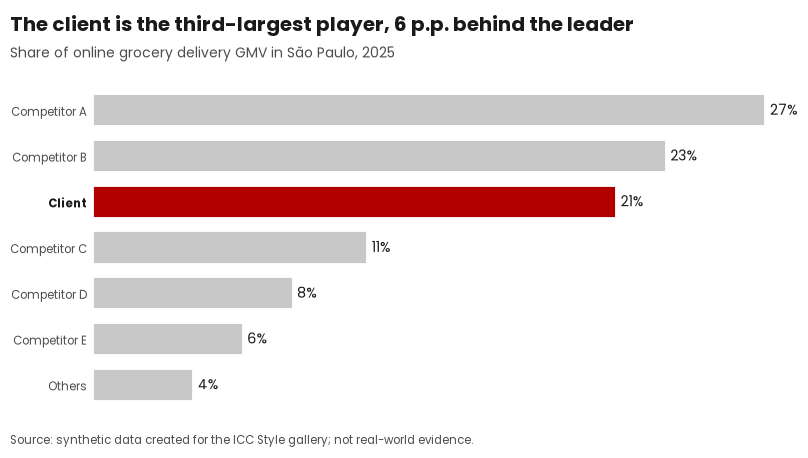

In [3]:
share = pd.Series(
    {
        "Competitor A": 0.27,
        "Competitor B": 0.23,
        "Client": 0.21,
        "Competitor C": 0.11,
        "Competitor D": 0.08,
        "Competitor E": 0.06,
    }
).sort_values()
share = pd.concat([pd.Series({"Others": 1 - share.sum()}), share])  # "Others" last

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [
    icc.PRIMARY_RED if name == "Client" else icc.LIGHT_GRAY for name in share.index
]
bars = ax.barh(share.index, share.to_numpy(), color=colors, height=0.68)
ax.bar_label(bars, fmt=icc.percent_formatter(decimals=0), padding=4)

ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.grid(False)
for label in ax.get_yticklabels():
    if label.get_text() == "Client":
        label.set_fontweight("bold")
        label.set_color(icc.BLACK)

gap = share["Competitor A"] - share["Client"]
icc.finalize_figure(
    fig,
    title=f"The client is the third-largest player, {gap * 100:.0f} p.p. behind the leader",
    subtitle="Share of online grocery delivery GMV in São Paulo, 2025",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "01_ranking.png", dpi=150)
plt.show()

### Multi-series comparison: two periods side by side

The prior year is gray and the current year red: the reader compares each pair and reads growth from the labels. The y-axis uses `brl_formatter` with `scale=1e6`, because the data are stored in millions of reais.

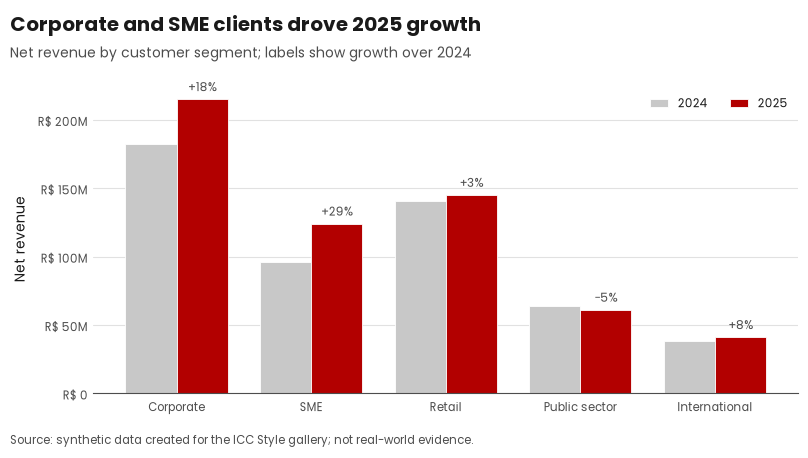

In [4]:
segments = ["Corporate", "SME", "Retail", "Public sector", "International"]
revenue_2024 = np.array([182, 96, 141, 64, 38])
revenue_2025 = np.array([215, 124, 145, 61, 41])
growth = revenue_2025 / revenue_2024 - 1

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(segments))
width = 0.38
ax.bar(x - width / 2, revenue_2024, width, color=icc.LIGHT_GRAY, label="2024")
bars_2025 = ax.bar(
    x + width / 2, revenue_2025, width, color=icc.PRIMARY_RED, label="2025"
)
ax.bar_label(
    bars_2025,
    labels=[icc.percent_formatter(decimals=0, signed=True)(g) for g in growth],
    padding=3,
    fontsize="small",
    color=icc.DARK_GRAY,
)

ax.set_xticks(x, segments)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_formatter(icc.brl_formatter(compact=True, scale=1e6))
ax.set_ylabel("Net revenue")
ax.legend(loc="upper right", ncols=2)

icc.finalize_figure(
    fig,
    title="Corporate and SME clients drove 2025 growth",
    subtitle="Net revenue by customer segment; labels show growth over 2024",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "02_multi_series.png", dpi=150)
plt.show()

### Rankings that changed: a dumbbell chart

When the question is *how positions moved*, a dumbbell chart shows both periods and the size of the change. Dots encode position, not length, so the axis does not need to start at zero; the axis label states the scale.

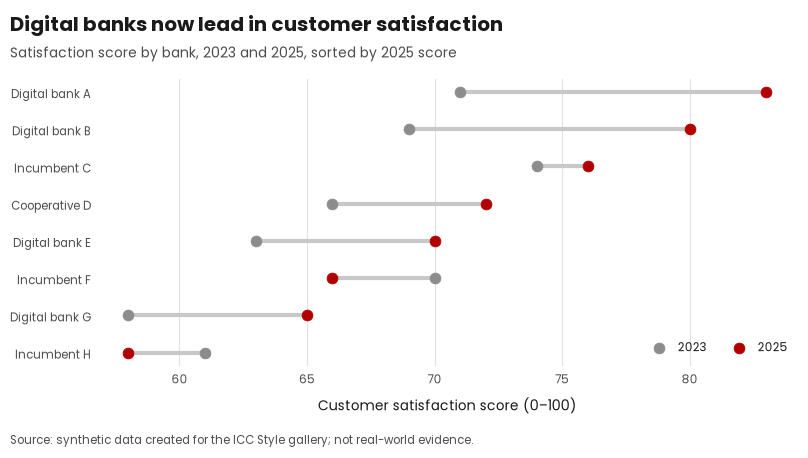

In [5]:
banks = pd.DataFrame(
    {
        "2023": [71, 69, 74, 66, 63, 70, 58, 61],
        "2025": [83, 80, 76, 72, 70, 66, 65, 58],
    },
    index=[
        "Digital bank A",
        "Digital bank B",
        "Incumbent C",
        "Cooperative D",
        "Digital bank E",
        "Incumbent F",
        "Digital bank G",
        "Incumbent H",
    ],
).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(banks))
ax.hlines(y, banks["2023"], banks["2025"], color=icc.LIGHT_GRAY, linewidth=3, zorder=1)
ax.scatter(banks["2023"], y, color=icc.GRAY, s=60, zorder=2, label="2023")
ax.scatter(banks["2025"], y, color=icc.PRIMARY_RED, s=60, zorder=3, label="2025")

ax.set_yticks(y, banks.index)
ax.set_xlabel("Customer satisfaction score (0–100)")
ax.grid(False, axis="y")
ax.grid(True, axis="x")
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(loc="lower right", ncols=2)

icc.finalize_figure(
    fig,
    title="Digital banks now lead in customer satisfaction",
    subtitle="Satisfaction score by bank, 2023 and 2025, sorted by 2025 score",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "03_dumbbell.png", dpi=150)
plt.show()

## 2. Understanding change over time

### Time series with one focus series

The client is the only colored line; peers are drawn thin and gray as context, with their median as a reference. Lines are labeled at their ends instead of with a legend. The y-axis does not start at zero. An index is read relative to its base of 100, which is drawn as a reference line.

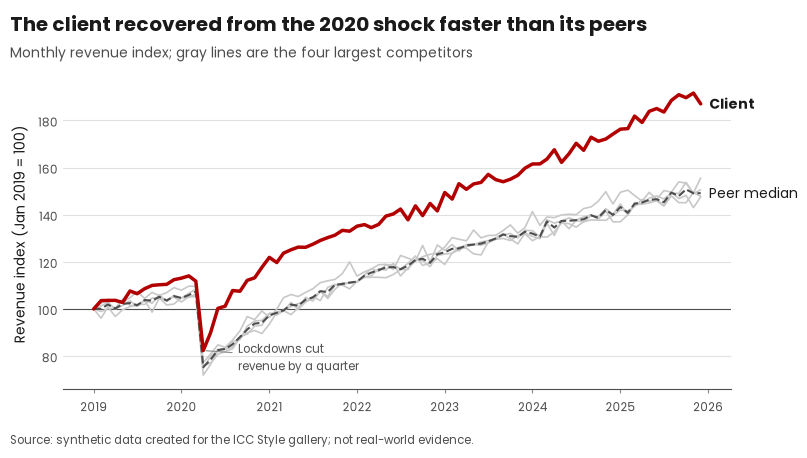

In [6]:
months = pd.date_range("2019-01-01", "2025-12-01", freq="MS")
t = np.arange(len(months))
shock = (months >= "2020-04-01") & (months <= "2020-12-01")


def revenue_index(trend, drop, recovery, noise):
    """Synthetic monthly revenue index with a 2020 shock and a recovery."""
    level = 100 * (1 + trend) ** t
    dip = np.where(months >= "2020-04-01", drop * np.exp(-recovery * (t - 15)), 0.0)
    series = level * (1 - dip) * (1 + rng.normal(0, noise, len(t)))
    return 100 * series / series[0]


client = revenue_index(0.0075, 0.28, 0.25, 0.012)
peers = pd.DataFrame(
    {f"Peer {i + 1}": revenue_index(0.005, 0.30, 0.08, 0.015) for i in range(4)},
    index=months,
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for column in peers:
    ax.plot(months, peers[column], color=icc.LIGHT_GRAY, linewidth=1.2)
peer_median = peers.median(axis=1)
ax.plot(months, peer_median, color=icc.DARK_GRAY, linewidth=1.5, linestyle="--")
ax.plot(months, client, color=icc.PRIMARY_RED, linewidth=2.5)
ax.axhline(100, color=icc.DARK_GRAY, linewidth=0.8, zorder=1)

for value, label, weight in [
    (client[-1], "Client", "bold"),
    (peer_median.iloc[-1], "Peer median", "normal"),
]:
    ax.annotate(
        label,
        xy=(months[-1], value),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontweight=weight,
    )
low = months[np.argmin(client)]
ax.annotate(
    "Lockdowns cut\nrevenue by a quarter",
    xy=(low, client.min()),
    xytext=(25, -5),
    textcoords="offset points",
    va="center",
    fontsize="small",
    color=icc.DARK_GRAY,
    arrowprops={"arrowstyle": "-", "color": icc.GRAY, "linewidth": 0.8},
)
ax.set_ylabel("Revenue index (Jan 2019 = 100)")

icc.finalize_figure(
    fig,
    title="The client recovered from the 2020 shock faster than its peers",
    subtitle="Monthly revenue index; gray lines are the four largest competitors",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "04_time_series.png", dpi=150)
plt.show()

### Comparison against a benchmark

The benchmark is dashed as well as gray, so the two series differ in more than color. The shaded area marks the periods of outperformance, and the title quantifies the result with a number computed from the data.

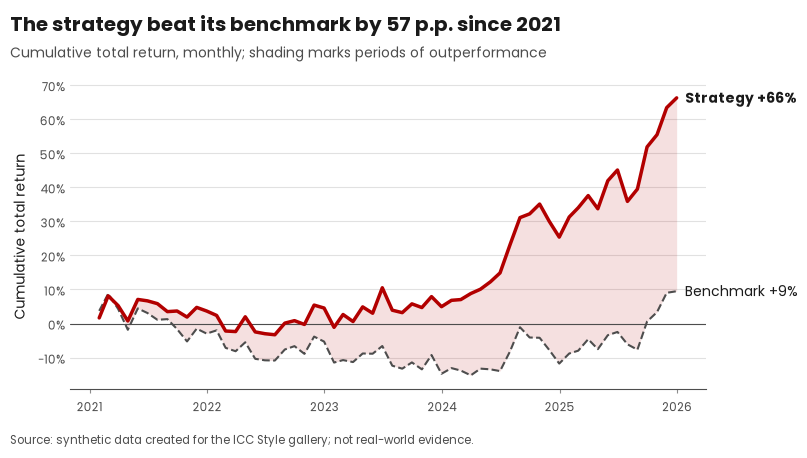

In [7]:
dates = pd.date_range("2021-01-31", "2025-12-31", freq="ME")
market = rng.normal(0.008, 0.045, len(dates))
benchmark_returns = market
strategy_returns = 0.002 + 0.9 * market + rng.normal(0, 0.015, len(dates))
benchmark = np.cumprod(1 + benchmark_returns) - 1
strategy = np.cumprod(1 + strategy_returns) - 1

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(
    dates,
    strategy,
    benchmark,
    where=strategy >= benchmark,
    interpolate=True,
    color=icc.PRIMARY_RED,
    alpha=0.12,
    linewidth=0,
)
ax.plot(dates, benchmark, color=icc.DARK_GRAY, linewidth=1.5, linestyle="--")
ax.plot(dates, strategy, color=icc.PRIMARY_RED, linewidth=2.5)
ax.axhline(0, color=icc.DARK_GRAY, linewidth=0.8, zorder=1)

pct = icc.percent_formatter(decimals=0, signed=True)
for value, label in [(strategy[-1], "Strategy"), (benchmark[-1], "Benchmark")]:
    ax.annotate(
        f"{label} {pct(value)}",
        xy=(dates[-1], value),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontweight="bold" if label == "Strategy" else "normal",
    )
ax.yaxis.set_major_formatter(icc.percent_formatter())
ax.set_ylabel("Cumulative total return")

icc.finalize_figure(
    fig,
    title=f"The strategy beat its benchmark by {(strategy[-1] - benchmark[-1]) * 100:.0f} p.p. since 2021",
    subtitle="Cumulative total return, monthly; shading marks periods of outperformance",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "05_benchmark.png", dpi=150)
plt.show()

## 3. Explaining financial performance

### Composition over time

A stacked bar chart shows both the total and its parts. The category the title talks about sits at the base, where its height is easiest to compare across years, and is the only one in red; its share is labeled inside the bars. The other categories use the analytical extension colors.

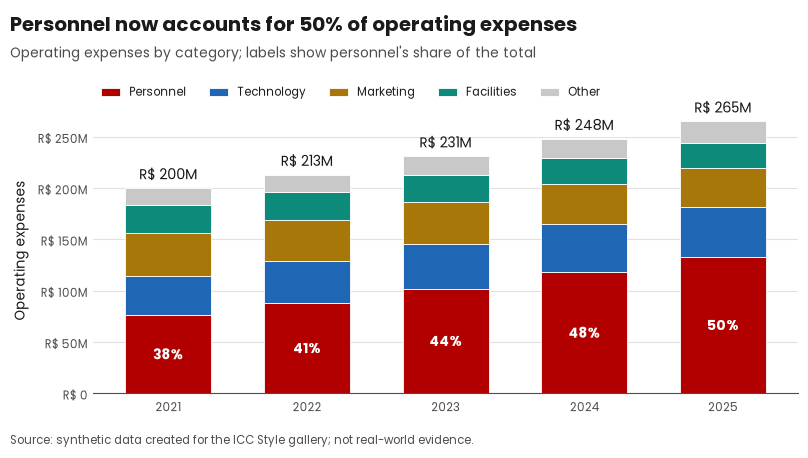

In [8]:
years = np.arange(2021, 2026)
opex = pd.DataFrame(
    {
        "Personnel": [76, 88, 102, 118, 133],
        "Technology": [38, 41, 44, 47, 49],
        "Marketing": [42, 40, 41, 39, 38],
        "Facilities": [28, 27, 26, 25, 24],
        "Other": [16, 17, 18, 19, 21],
    },
    index=years,
)
colors = [icc.PRIMARY_RED, icc.BLUE, icc.GOLD, icc.TEAL, icc.LIGHT_GRAY]

fig, ax = plt.subplots(figsize=(8, 4.5))
bottom = np.zeros(len(opex))
for (category, values), color in zip(opex.items(), colors, strict=True):
    ax.bar(opex.index, values, bottom=bottom, color=color, width=0.62, label=category)
    bottom += values
personnel_share = opex["Personnel"] / opex.sum(axis=1)
ax.bar_label(
    ax.containers[0],
    labels=[icc.percent_formatter(decimals=0)(s) for s in personnel_share],
    label_type="center",
    color=icc.WHITE,
    fontweight="bold",
)
totals = opex.sum(axis=1)
ax.bar_label(
    ax.containers[-1],
    labels=[icc.brl_formatter(decimals=0, compact=True, scale=1e6)(v) for v in totals],
    padding=3,
)

ax.set_xticks(years)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_formatter(icc.brl_formatter(compact=True, scale=1e6))
ax.set_ylabel("Operating expenses")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=5, borderaxespad=0.3)

icc.finalize_figure(
    fig,
    title=f"Personnel now accounts for {personnel_share.iloc[-1]:.0%} of operating expenses",
    subtitle="Operating expenses by category; labels show personnel's share of the total",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "06_composition.png", dpi=150)
plt.show()

### Waterfall: bridging two results

A waterfall explains how one figure became another. Totals are dark gray and start at zero; increases are blue and decreases red. Signed labels repeat the direction in text, so color is not the only cue. Thin connectors guide the eye from bar to bar.

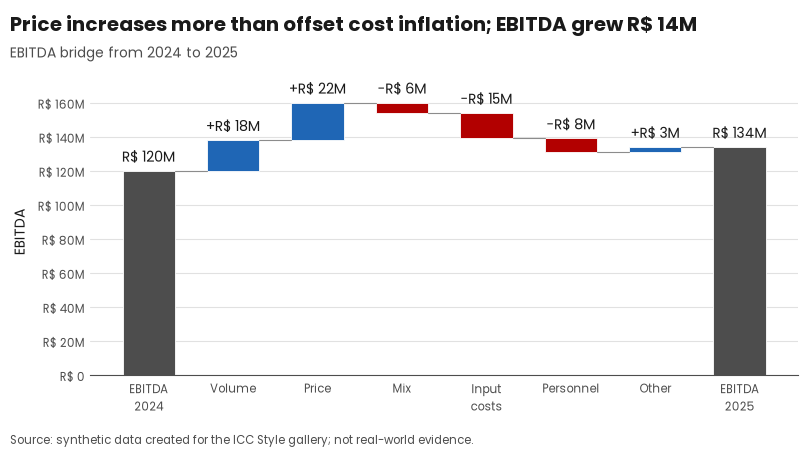

In [9]:
bridge = pd.Series(
    {
        "Volume": 18,
        "Price": 22,
        "Mix": -6,
        "Input costs": -15,
        "Personnel": -8,
        "Other": 3,
    }
)
start, end = 120, 120 + bridge.sum()
labels = ["EBITDA\n2024", *bridge.index.str.replace(" ", "\n"), "EBITDA\n2025"]
running = start + np.r_[0, bridge.cumsum()]  # level before each step, then the end
heights = [start, *bridge.abs(), end]
bottoms = [0, *np.minimum(running[:-1], running[1:]), 0]
colors = [
    icc.DARK_GRAY,
    *[icc.BLUE if v > 0 else icc.PRIMARY_RED for v in bridge],
    icc.DARK_GRAY,
]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(labels))
bars = ax.bar(x, heights, bottom=bottoms, color=colors, width=0.62)

brl = icc.brl_formatter(compact=True, scale=1e6)
label = icc.brl_formatter(decimals=0, compact=True, scale=1e6)
signed = icc.brl_formatter(decimals=0, compact=True, scale=1e6, signed=True)
values = [start, *bridge, end]
texts = [
    label(v) if i in (0, len(values) - 1) else signed(v) for i, v in enumerate(values)
]
ax.bar_label(bars, labels=texts, padding=3)

for i, level in enumerate(running):
    ax.plot(
        [x[i] + 0.31, x[i + 1] - 0.31], [level, level], color=icc.GRAY, linewidth=0.8
    )

ax.set_xticks(x, labels)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_formatter(brl)
ax.set_ylabel("EBITDA")

icc.finalize_figure(
    fig,
    title=f"Price increases more than offset cost inflation; EBITDA grew {label(end - start)}",
    subtitle="EBITDA bridge from 2024 to 2025",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "07_waterfall.png", dpi=150)
plt.show()

## 4. Understanding relationships

### Scatterplot with a regression line and confidence interval

Seaborn works with the theme without further configuration. Observations are gray so that the fitted line, which carries the message, stands out in red with its 95% confidence band. The title quantifies the slope, and the subtitle reminds the reader that this is an association, not a causal effect. Scatterplots get gridlines on both axes.

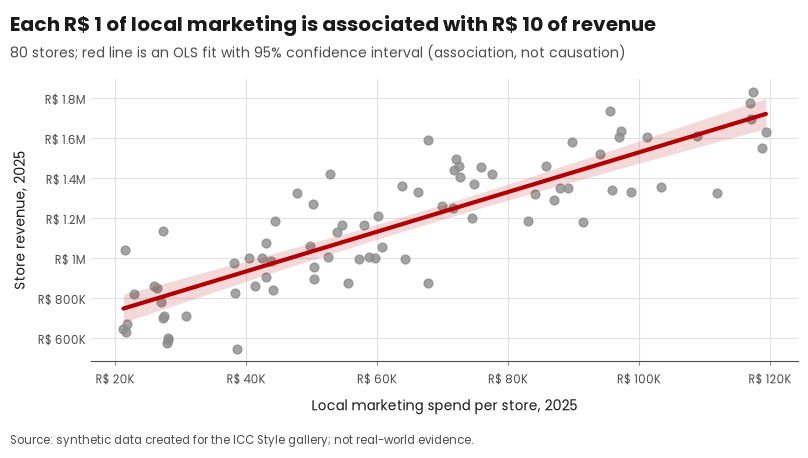

In [10]:
stores = pd.DataFrame({"marketing": rng.uniform(20, 120, 80)})  # R$ thousand
stores["revenue"] = (
    0.6 + 0.009 * stores["marketing"] + rng.normal(0, 0.18, 80)
)  # R$ million

slope = np.polyfit(stores["marketing"] * 1e3, stores["revenue"] * 1e6, 1)[0]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(
    data=stores,
    x="marketing",
    y="revenue",
    ci=95,
    ax=ax,
    scatter_kws={"color": icc.GRAY, "s": 40},
    line_kws={"color": icc.PRIMARY_RED},
)
ax.grid(True, axis="both")
ax.xaxis.set_major_formatter(icc.brl_formatter(compact=True, scale=1e3))
ax.yaxis.set_major_formatter(icc.brl_formatter(compact=True, scale=1e6))
ax.set_xlabel("Local marketing spend per store, 2025")
ax.set_ylabel("Store revenue, 2025")

icc.finalize_figure(
    fig,
    title=f"Each R$ 1 of local marketing is associated with R$ {slope:.0f} of revenue",
    subtitle="80 stores; red line is an OLS fit with 95% confidence interval (association, not causation)",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "08_scatter_regression.png", dpi=150)
plt.show()

### Correlation matrix with a diverging colormap

Correlations have a meaningful midpoint (zero), so they use the diverging `icc_diverging` colormap, pinned to the full −1 to 1 range so that color intensity is comparable across charts. Only the lower triangle is shown, and cell labels use `number_formatter`, which writes a true minus sign.

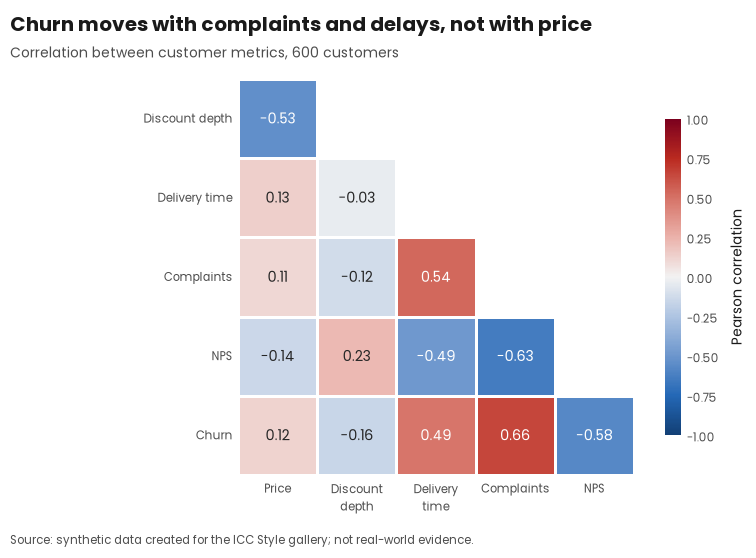

In [11]:
variables = ["Price", "Discount depth", "Delivery time", "Complaints", "NPS", "Churn"]
target = np.array(
    [
        [1.00, -0.55, 0.05, 0.10, -0.15, 0.08],
        [-0.55, 1.00, -0.05, -0.10, 0.20, -0.12],
        [0.05, -0.05, 1.00, 0.55, -0.45, 0.50],
        [0.10, -0.10, 0.55, 1.00, -0.65, 0.70],
        [-0.15, 0.20, -0.45, -0.65, 1.00, -0.60],
        [0.08, -0.12, 0.50, 0.70, -0.60, 1.00],
    ]
)
customers = pd.DataFrame(
    rng.multivariate_normal(np.zeros(len(variables)), target, size=600),
    columns=variables,
)
corr = customers.corr().iloc[1:, :-1]  # drop the empty first row and last column
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fmt = icc.number_formatter(decimals=2)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(
    corr,
    mask=mask,
    cmap="icc_diverging",
    vmin=-1,
    vmax=1,
    center=0,
    annot=corr.map(fmt),
    fmt="",
    linewidths=2,
    linecolor=icc.WHITE,
    square=True,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
    ax=ax,
)
ax.grid(False)  # gridlines would show through the masked cells
ax.tick_params(length=0)
ax.tick_params(axis="y", rotation=0)
ax.set_xticklabels(
    [label.get_text().replace(" ", "\n") for label in ax.get_xticklabels()]
)

icc.finalize_figure(
    fig,
    title="Churn moves with complaints and delays, not with price",
    subtitle="Correlation between customer metrics, 600 customers",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "09_correlation.png", dpi=150)
plt.show()

## 5. Evaluating uncertainty

The next three charts use the same synthetic investment case: a project whose net present value (NPV) depends on volume, price, unit cost, discount rate (WACC), capital expenditure and terminal growth.

In [12]:
HORIZON = np.arange(1, 11)
BASE = {
    "volume": 1.0,
    "price": 1.0,
    "unit_cost": 1.0,
    "wacc": 0.13,
    "capex": 290.0,
    "terminal_growth": 0.03,
}


def project_npv(**drivers):
    """NPV in R$ million; each driver may be a scalar or an array of scenarios."""
    d = {key: np.asarray(drivers.get(key, value), float) for key, value in BASE.items()}
    t = HORIZON.reshape(-1, *[1] * np.broadcast(*d.values()).ndim)
    cash = 100 * d["volume"] * (d["price"] - 0.73 * d["unit_cost"]) * 1.06**t
    discount = (1 + d["wacc"]) ** t
    terminal = (
        cash[-1] * (1 + d["terminal_growth"]) / (d["wacc"] - d["terminal_growth"])
    )
    return (cash / discount).sum(axis=0) + terminal / discount[-1] - d["capex"]


base_npv = project_npv()
base_npv

np.float64(49.87452999535981)

### Distribution of Monte Carlo outcomes

A histogram of 10,000 simulated outcomes. Bins below zero, which represent the scenarios that destroy value, are red; the rest are gray. Dashed lines mark the 5th, 50th and 95th percentiles. The y-axis shows the share of simulations, not raw counts, so it does not depend on the number of runs.

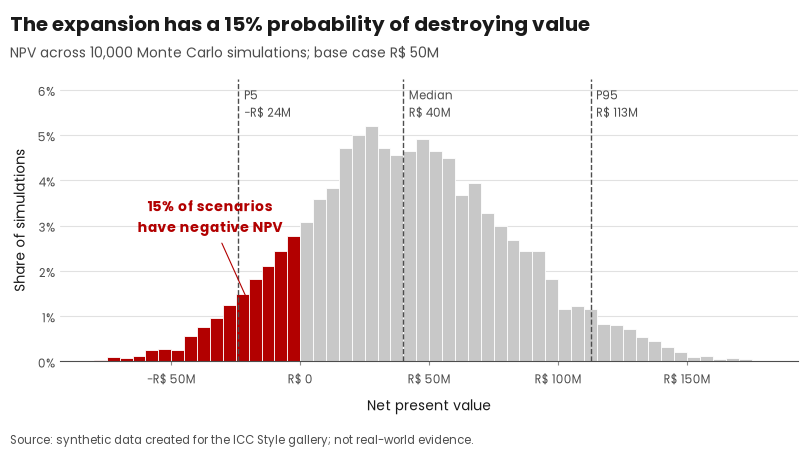

In [13]:
n = 10_000
npv = project_npv(
    volume=rng.normal(1, 0.06, n),
    price=rng.normal(1, 0.02, n),
    unit_cost=rng.normal(1, 0.015, n),
    wacc=rng.normal(0.13, 0.005, n),
    capex=rng.triangular(280, 290, 330, n),
)
p_loss = (npv < 0).mean()
p5, p50, p95 = np.percentile(npv, [5, 50, 95])
brl = icc.brl_formatter(compact=True, scale=1e6)
label = icc.brl_formatter(decimals=0, compact=True, scale=1e6)

fig, ax = plt.subplots(figsize=(8, 4.5))
counts, edges, patches = ax.hist(
    npv, bins=np.arange(-80, 181, 5), weights=np.full(n, 1 / n)
)
for patch, left in zip(patches, edges[:-1], strict=True):
    patch.set_facecolor(icc.PRIMARY_RED if left < 0 else icc.LIGHT_GRAY)

top = counts.max()
for value, name in [(p5, "P5"), (p50, "Median"), (p95, "P95")]:
    ax.axvline(value, color=icc.DARK_GRAY, linewidth=1, linestyle="--")
    ax.annotate(
        f"{name}\n{label(value)}",
        xy=(value, top * 1.02),
        xytext=(4, 0),
        textcoords="offset points",
        va="bottom",
        fontsize="small",
        color=icc.DARK_GRAY,
    )
ax.annotate(
    f"{p_loss:.0%} of scenarios\nhave negative NPV",
    xy=(-20, top * 0.25),
    xytext=(-35, top * 0.55),
    ha="center",
    color=icc.PRIMARY_RED,
    fontweight="bold",
    arrowprops={"arrowstyle": "-", "color": icc.PRIMARY_RED, "linewidth": 0.8},
)
ax.set_ylim(0, top * 1.2)
ax.xaxis.set_major_formatter(brl)
ax.yaxis.set_major_formatter(icc.percent_formatter())
ax.set_xlabel("Net present value")
ax.set_ylabel("Share of simulations")

icc.finalize_figure(
    fig,
    title=f"The expansion has a {p_loss:.0%} probability of destroying value",
    subtitle=f"NPV across {n:,} Monte Carlo simulations; base case {label(base_npv)}",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "10_monte_carlo.png", dpi=150)
plt.show()

### Fan chart: a projection with uncertainty bands

History is a solid black line; the projection is a red median with nested 50% and 90% bands taken from the sequential red colormap. Lighter means less likely. Bands are labeled directly.

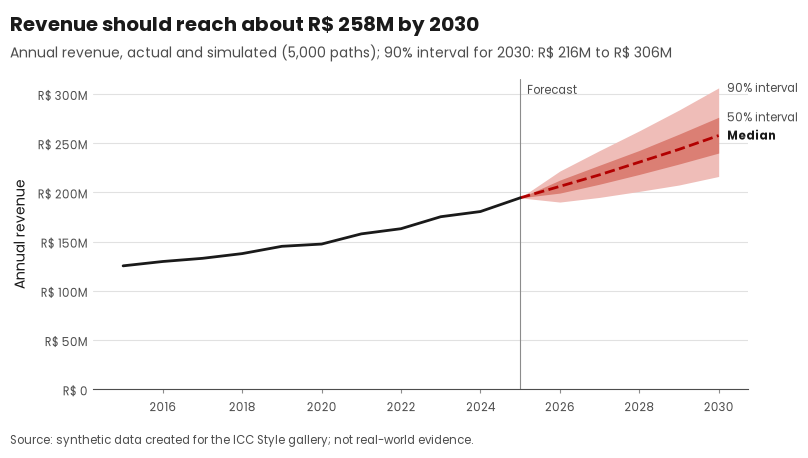

In [14]:
history_years = np.arange(2015, 2026)
history = 120 * np.cumprod(1 + rng.normal(0.055, 0.03, len(history_years)))
forecast_years = np.arange(2025, 2031)
paths = 5_000
growth = rng.normal(0.06, 0.05, (paths, len(forecast_years) - 1))
simulated = history[-1] * np.cumprod(np.c_[np.ones(paths), 1 + growth], axis=1)
bands = np.percentile(simulated, [5, 25, 50, 75, 95], axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(
    forecast_years, bands[0], bands[4], color=icc.SEQUENTIAL_CMAP(0.2), linewidth=0
)
ax.fill_between(
    forecast_years, bands[1], bands[3], color=icc.SEQUENTIAL_CMAP(0.45), linewidth=0
)
ax.plot(forecast_years, bands[2], color=icc.PRIMARY_RED, linestyle="--")
ax.plot(history_years, history, color=icc.BLACK)
ax.axvline(2025, color=icc.GRAY, linewidth=0.8, zorder=1)
ax.annotate(
    "Forecast",
    xy=(2025, 1),
    xycoords=("data", "axes fraction"),
    xytext=(5, -2),
    textcoords="offset points",
    va="top",
    fontsize="small",
    color=icc.DARK_GRAY,
)

for band, label in [(bands[4], "90% interval"), (bands[3], "50% interval")]:
    ax.annotate(
        label,
        xy=(2030, band[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize="small",
        color=icc.DARK_GRAY,
    )
ax.annotate(
    "Median",
    xy=(2030, bands[2][-1]),
    xytext=(6, 0),
    textcoords="offset points",
    va="center",
    fontsize="small",
    fontweight="bold",
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(icc.brl_formatter(compact=True, scale=1e6))
ax.set_ylim(bottom=0)
ax.set_ylabel("Annual revenue")

brl = icc.brl_formatter(decimals=0, compact=True, scale=1e6)
icc.finalize_figure(
    fig,
    title=f"Revenue should reach about {brl(bands[2][-1])} by 2030",
    subtitle=(
        f"Annual revenue, actual and simulated (5,000 paths); "
        f"90% interval for 2030: {brl(bands[0][-1])} to {brl(bands[4][-1])}"
    ),
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "11_fan_chart.png", dpi=150)
plt.show()

### Sensitivity analysis: a tornado chart

Each bar shows the NPV when one driver moves to its low or high case while the others stay at the base case. Drivers are sorted by impact. Downside bars are red, upside bars blue, and every bar end is labeled with its value.

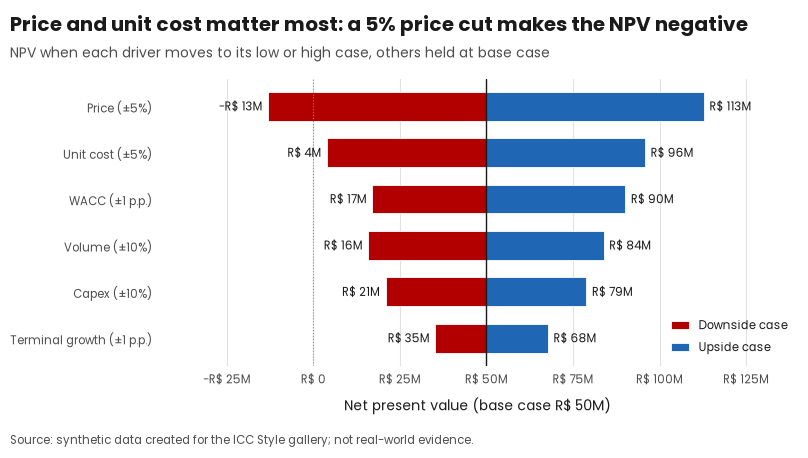

In [15]:
cases = {
    "Price (±5%)": ("price", 0.95, 1.05),
    "Unit cost (±5%)": ("unit_cost", 1.05, 0.95),
    "WACC (±1 p.p.)": ("wacc", 0.14, 0.12),
    "Volume (±10%)": ("volume", 0.90, 1.10),
    "Capex (±10%)": ("capex", 319.0, 261.0),
    "Terminal growth (±1 p.p.)": ("terminal_growth", 0.02, 0.04),
}
sensitivity = pd.DataFrame(
    {
        name: {
            "downside": project_npv(**{key: low}),
            "upside": project_npv(**{key: high}),
        }
        for name, (key, low, high) in cases.items()
    }
).T
sensitivity = sensitivity.assign(range=lambda d: d.upside - d.downside).sort_values(
    "range"
)

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(sensitivity))
down = ax.barh(
    y,
    sensitivity["downside"] - base_npv,
    left=base_npv,
    color=icc.PRIMARY_RED,
    height=0.62,
    label="Downside case",
)
up = ax.barh(
    y,
    sensitivity["upside"] - base_npv,
    left=base_npv,
    color=icc.BLUE,
    height=0.62,
    label="Upside case",
)
brl = icc.brl_formatter(compact=True, scale=1e6)
label = icc.brl_formatter(decimals=0, compact=True, scale=1e6)
ax.bar_label(
    down,
    labels=[label(v) for v in sensitivity["downside"]],
    padding=4,
    fontsize="small",
)
ax.bar_label(
    up, labels=[label(v) for v in sensitivity["upside"]], padding=4, fontsize="small"
)
ax.set_xlim(-45, 140)  # room for the labels at the bar ends
ax.axvline(base_npv, color=icc.BLACK, linewidth=1)
ax.axvline(0, color=icc.GRAY, linewidth=0.8, linestyle=":")

ax.set_yticks(y, sensitivity.index)
ax.grid(False, axis="y")
ax.grid(True, axis="x")
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.xaxis.set_major_formatter(brl)
ax.set_xlabel(f"Net present value (base case {label(base_npv)})")
ax.legend(loc="lower right")

icc.finalize_figure(
    fig,
    title="Price and unit cost matter most: a 5% price cut makes the NPV negative",
    subtitle="NPV when each driver moves to its low or high case, others held at base case",
    source=SOURCE,
)
icc.save_figure(fig, FIGURES / "12_tornado.png", dpi=150)
plt.show()

## 6. Communicating a conclusion

### A slide: the `presentation` context

For slides, `theme_context("presentation")` enlarges type and line widths and uses a 16:9 figure. The action title states the conclusion, the forecast period is shaded and labeled, and one annotation marks the year in which digital sales pass 50%. The figure is created, saved and shown inside the `with` block so that every element uses the presentation settings. It is exported as PNG (for PowerPoint or Google Slides) and PDF (for LaTeX or Beamer).

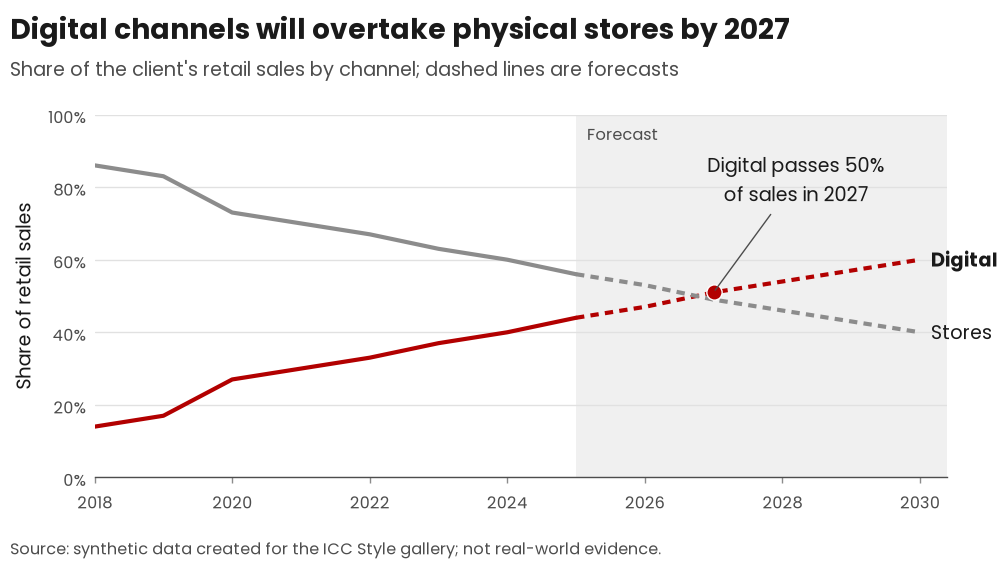

In [16]:
channel_years = np.arange(2018, 2031)
digital = np.array(
    [0.14, 0.17, 0.27, 0.30, 0.33, 0.37, 0.40, 0.44, 0.47, 0.51, 0.54, 0.57, 0.60]
)
stores_share = 1 - digital
is_forecast = channel_years >= 2025

with icc.theme_context("presentation"):
    fig, ax = plt.subplots()
    ax.axvspan(2025, 2030.4, color=icc.PALE_GRAY, alpha=0.6, linewidth=0, zorder=0)
    ax.annotate(
        "Forecast",
        xy=(2025, 1),
        xycoords=("data", "axes fraction"),
        xytext=(8, -6),
        textcoords="offset points",
        va="top",
        fontsize="small",
        color=icc.DARK_GRAY,
    )
    for share_values, color, label in [
        (digital, icc.PRIMARY_RED, "Digital"),
        (stores_share, icc.GRAY, "Stores"),
    ]:
        ax.plot(
            channel_years[~is_forecast | (channel_years == 2025)],
            share_values[channel_years <= 2025],
            color=color,
        )
        ax.plot(
            channel_years[is_forecast],
            share_values[is_forecast],
            color=color,
            linestyle=(0, (2, 1.5)),
        )
        ax.annotate(
            label,
            xy=(channel_years[-1], share_values[-1]),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontweight="bold" if label == "Digital" else "normal",
        )
    ax.plot(
        [2027],
        [0.51],
        marker="o",
        color=icc.PRIMARY_RED,
        markeredgecolor=icc.WHITE,
        markersize=11,
    )
    ax.annotate(
        "Digital passes 50%\nof sales in 2027",
        xy=(2027, 0.51),
        xytext=(2028.2, 0.74),
        ha="center",
        va="bottom",
        arrowprops={"arrowstyle": "-", "color": icc.DARK_GRAY, "linewidth": 1},
    )

    ax.set_xlim(2018, 2030.4)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(icc.percent_formatter())
    ax.set_ylabel("Share of retail sales")

    icc.finalize_figure(
        fig,
        title="Digital channels will overtake physical stores by 2027",
        subtitle="Share of the client's retail sales by channel; dashed lines are forecasts",
        source=SOURCE,
    )
    icc.save_figure(fig, FIGURES / "13_slide", formats=("png", "pdf"), dpi=200)
    plt.show()

### A website article: the `publication` context, in Portuguese

Articles on the ICC website are often written in Portuguese. The formatters take `locale="pt-BR"` for Brazilian separators, and `bps_formatter` accepts the Portuguese unit. The `publication` context produces a figure that fits a text column at 100% scale. The SVG keeps text as outlines (the default), so it looks identical in every browser.

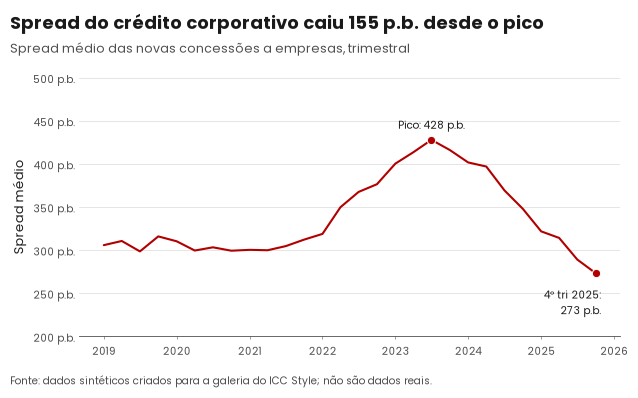

In [17]:
quarters = pd.period_range("2019Q1", "2025Q4", freq="Q").to_timestamp()
q = np.arange(len(quarters))
spread = (
    310 + 140 * np.exp(-((q - 18.5) ** 2) / 30) - 1.5 * q + rng.normal(0, 6, len(q))
)
peak = int(np.argmax(spread))
drop = spread[peak] - spread[-1]
bps = icc.bps_formatter(scale=1, unit="p.b.", locale="pt-BR")

with icc.theme_context("publication"):
    fig, ax = plt.subplots()
    ax.plot(quarters, spread, color=icc.PRIMARY_RED)
    ax.plot(
        quarters[[peak, -1]],
        spread[[peak, -1]],
        linestyle="none",
        marker="o",
        color=icc.PRIMARY_RED,
        markeredgecolor=icc.WHITE,
        markersize=6,
    )
    ax.annotate(
        f"Pico: {bps(spread[peak])}",
        xy=(quarters[peak], spread[peak]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize="small",
    )
    ax.annotate(
        f"4º tri 2025:\n{bps(spread[-1])}",
        xy=(quarters[-1], spread[-1]),
        xytext=(4, -10),
        textcoords="offset points",
        ha="right",
        va="top",
        fontsize="small",
    )
    ax.yaxis.set_major_formatter(bps)
    ax.set_ylabel("Spread médio")
    ax.set_ylim(200, 500)

    icc.finalize_figure(
        fig,
        title=f"Spread do crédito corporativo caiu {drop:.0f} p.b. desde o pico",
        subtitle="Spread médio das novas concessões a empresas, trimestral",
        source="Fonte: dados sintéticos criados para a galeria do ICC Style; não são dados reais.",
    )
    icc.save_figure(fig, FIGURES / "14_article", formats=("png", "svg"), dpi=200)
    plt.show()

## Appendix: palette reference

The four official ICC brand colors, followed by the visualization extensions this package adds for analytical charts.

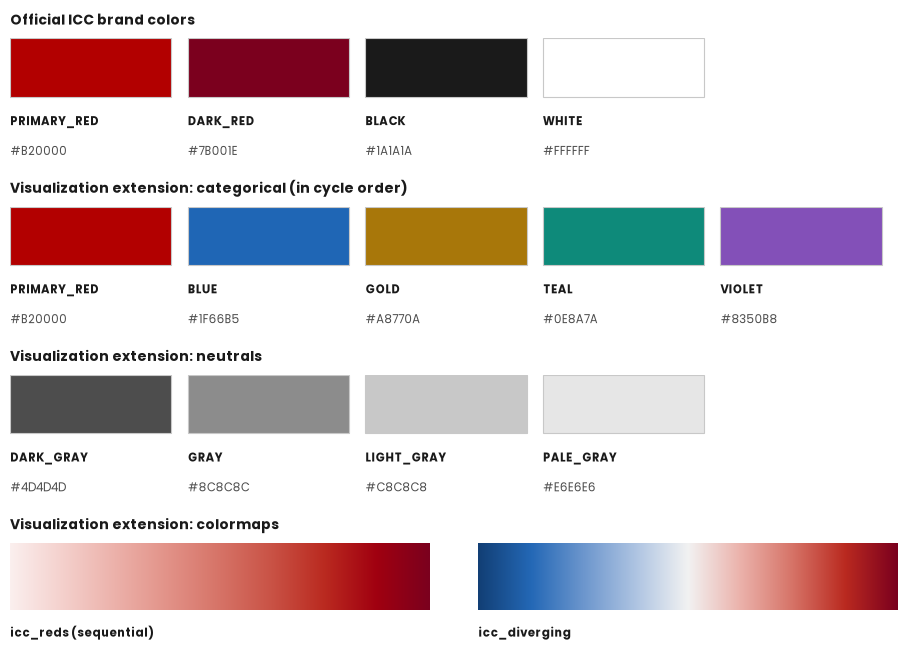

In [18]:
groups = [
    (
        "Official ICC brand colors",
        [
            ("PRIMARY_RED", icc.PRIMARY_RED),
            ("DARK_RED", icc.DARK_RED),
            ("BLACK", icc.BLACK),
            ("WHITE", icc.WHITE),
        ],
    ),
    (
        "Visualization extension: categorical (in cycle order)",
        [
            ("PRIMARY_RED", icc.PRIMARY_RED),
            ("BLUE", icc.BLUE),
            ("GOLD", icc.GOLD),
            ("TEAL", icc.TEAL),
            ("VIOLET", icc.VIOLET),
        ],
    ),
    (
        "Visualization extension: neutrals",
        [
            ("DARK_GRAY", icc.DARK_GRAY),
            ("GRAY", icc.GRAY),
            ("LIGHT_GRAY", icc.LIGHT_GRAY),
            ("PALE_GRAY", icc.PALE_GRAY),
        ],
    ),
]

fig = plt.figure(figsize=(9, 6.6))
grid = fig.add_gridspec(len(groups) + 1, 1, height_ratios=[1, 1, 1, 0.9])
for row, (heading, swatches) in enumerate(groups):
    ax = fig.add_subplot(grid[row])
    for i, (name, color) in enumerate(swatches):
        ax.add_patch(
            plt.Rectangle(
                (i * 1.1, 0.45),
                1,
                0.55,
                facecolor=color,
                edgecolor=icc.LIGHT_GRAY,
                linewidth=0.8,
            )
        )
        ax.text(i * 1.1, 0.3, name, fontsize="small", fontweight="bold", va="top")
        ax.text(i * 1.1, 0.02, color, fontsize="small", color=icc.DARK_GRAY, va="top")
    ax.set_xlim(0, 5 * 1.1)
    ax.set_ylim(-0.2, 1)
    ax.set_title(heading, fontsize="medium")
    ax.axis("off")

ax = fig.add_subplot(grid[-1])
gradient = np.linspace(0, 1, 256)[None, :]
ax.imshow(gradient, aspect="auto", cmap="icc_reds", extent=(0, 2.6, 0.3, 1))
ax.imshow(gradient, aspect="auto", cmap="icc_diverging", extent=(2.9, 5.5, 0.3, 1))
ax.text(0, 0.15, "icc_reds (sequential)", fontsize="small", fontweight="bold", va="top")
ax.text(2.9, 0.15, "icc_diverging", fontsize="small", fontweight="bold", va="top")
ax.set_xlim(0, 5.5)
ax.set_ylim(-0.2, 1)
ax.set_title("Visualization extension: colormaps", fontsize="medium")
ax.axis("off")

icc.save_figure(fig, FIGURES / "00_palette.png", dpi=150)
plt.show()